# 02 - Electricity EDA (BijliCast)

**CT-378 Phase 2: EDA - step 2**

Covers **distributions**, **outliers** and **target balance**, plus city-level
load behaviour. Produces 4 plots.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Locate repo root (works whether run from notebooks/ or repo root)
ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)
print("Figures  :", FIG)

df = pd.read_parquet(ROOT / "data" / "processed" / "hourly_combined.parquet")
df["datetime"] = pd.to_datetime(df["datetime"])
print("Dataset:", df.shape)
df.head()

Repo root: D:\BijliCast
Figures  : D:\BijliCast\reports\figures


Dataset: (515786, 12)


,datetime,usage_kw,house_id,city,temperature,humidity,dew,precipitation,wind_speed,wind_direction,pressure,solar_radiation
0,2023-11-01 00:00:00,0.525333,House#41,Islamabad,17.9,75,13.5,0.0,5.2,344,957.3,0.0
1,2023-11-01 01:00:00,0.560500,House#41,Islamabad,18.2,72,13.2,0.0,6.2,339,957.3,0.0
2,2023-11-01 02:00:00,0.593833,House#41,Islamabad,18.6,70,13.1,0.0,5.0,330,957.3,0.0
3,2023-11-01 03:00:00,0.587667,House#41,Islamabad,19.3,67,13.1,0.0,3.7,331,957.4,0.0
4,2023-11-01 04:00:00,0.594000,House#41,Islamabad,17.9,74,13.2,0.0,3.9,326,957.1,0.0


## 1. Usage summary by city

In [2]:
summary = df.groupby("city")["usage_kw"].agg(
    hours="count",
    mean="mean",
    median="median",
    p95=lambda s: s.quantile(0.95),
    max="max",
    zero_frac_pct=lambda s: (s == 0).mean() * 100,
).round(3)
summary

,hours,mean,median,p95,max,zero_frac_pct
city,,,,,,
Islamabad,82688,0.585,0.316,2.144,11.520,4.285
Karachi,87075,0.960,0.630,2.840,9.271,0.080
Lahore,83748,0.987,0.640,3.034,10.753,0.911
Multan,86603,0.760,0.474,2.413,12.662,0.196
Peshawar,83715,0.649,0.395,2.358,7.285,5.362
Skardu,78982,0.372,0.009,2.252,7.241,5.808


### Plot 3 - Average 24-hour load profile by city

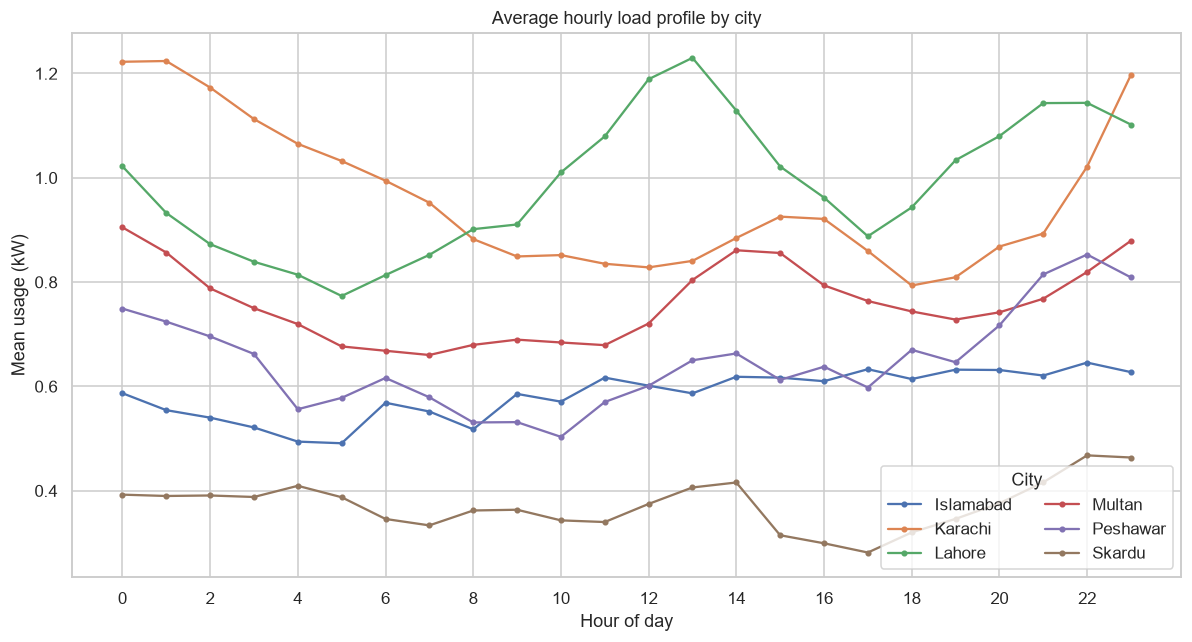

In [3]:
df["hour"] = df["datetime"].dt.hour
prof = df.groupby(["city", "hour"])["usage_kw"].mean().unstack(0)
plt.figure(figsize=(11, 6))
for c in prof.columns:
    plt.plot(prof.index, prof[c], marker="o", ms=3, label=c)
plt.title("Average hourly load profile by city")
plt.xlabel("Hour of day")
plt.ylabel("Mean usage (kW)")
plt.xticks(range(0, 24, 2))
plt.legend(title="City", ncol=2)
plt.tight_layout()
plt.savefig(FIG / "02_load_profile_by_city.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 4 - Usage distribution by city (boxplot)

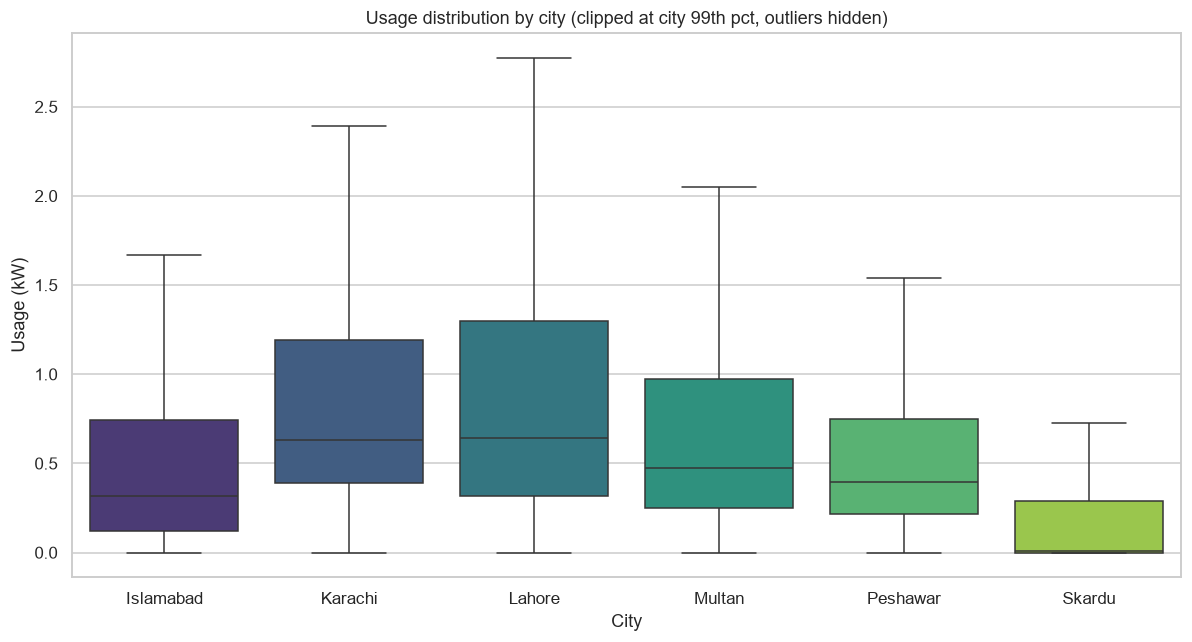

In [4]:
sub = df.dropna(subset=["usage_kw"]).copy()
sub["usage_clip"] = sub.groupby("city")["usage_kw"].transform(lambda s: s.clip(upper=s.quantile(0.99)))
plt.figure(figsize=(11, 6))
sns.boxplot(data=sub, x="city", y="usage_clip", hue="city", palette="viridis", legend=False, showfliers=False)
plt.title("Usage distribution by city (clipped at city 99th pct, outliers hidden)")
plt.xlabel("City")
plt.ylabel("Usage (kW)")
plt.tight_layout()
plt.savefig(FIG / "02_city_usage_boxplot.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 5 - Outlier share per house (IQR rule)

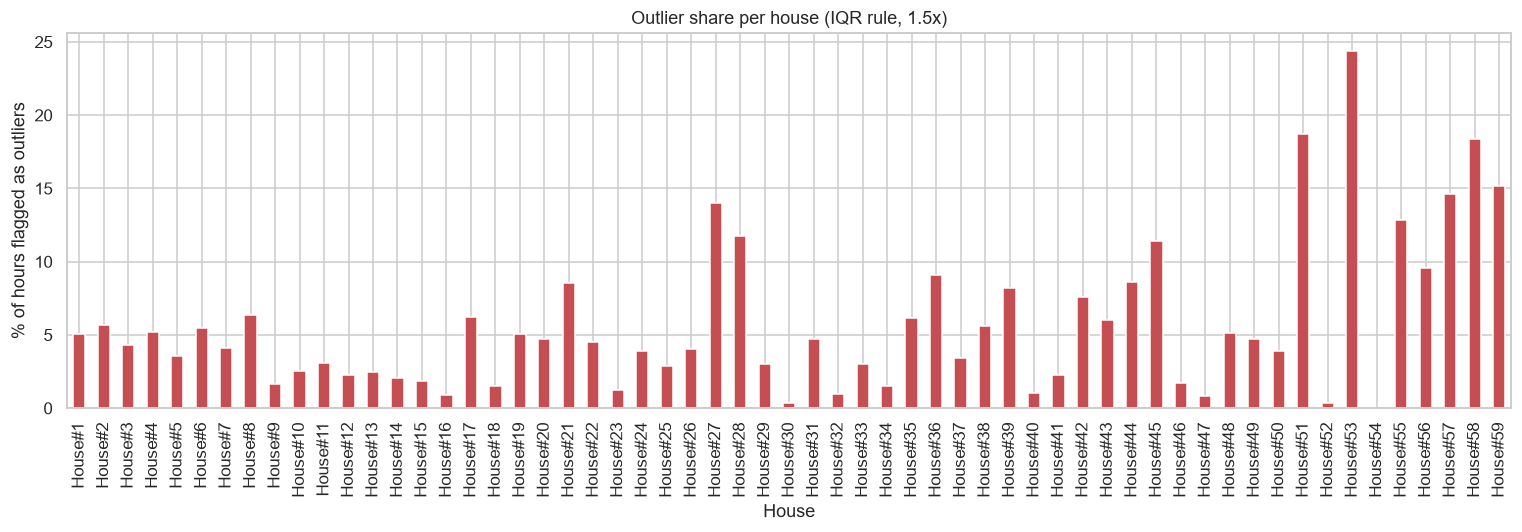

Houses with >5% IQR outliers: 26 of 59


In [5]:
def iqr_outlier_frac(s):
    s = s.dropna()
    if len(s) == 0:
        return np.nan
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return 0.0
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).mean() * 100

out = df.groupby("house_id")["usage_kw"].apply(iqr_outlier_frac)
out = out.reindex(sorted(out.index, key=lambda h: int(re.search(r"\d+", h).group())))
plt.figure(figsize=(14, 5))
out.plot(kind="bar", color="#c44e52")
plt.title("Outlier share per house (IQR rule, 1.5x)")
plt.xlabel("House")
plt.ylabel("% of hours flagged as outliers")
plt.tight_layout()
plt.savefig(FIG / "02_outliers_by_house.png", dpi=220, bbox_inches="tight")
plt.show()
print("Houses with >5% IQR outliers:", int((out > 5).sum()), "of", len(out))

### Plot 6 - Target balance (usage bins)

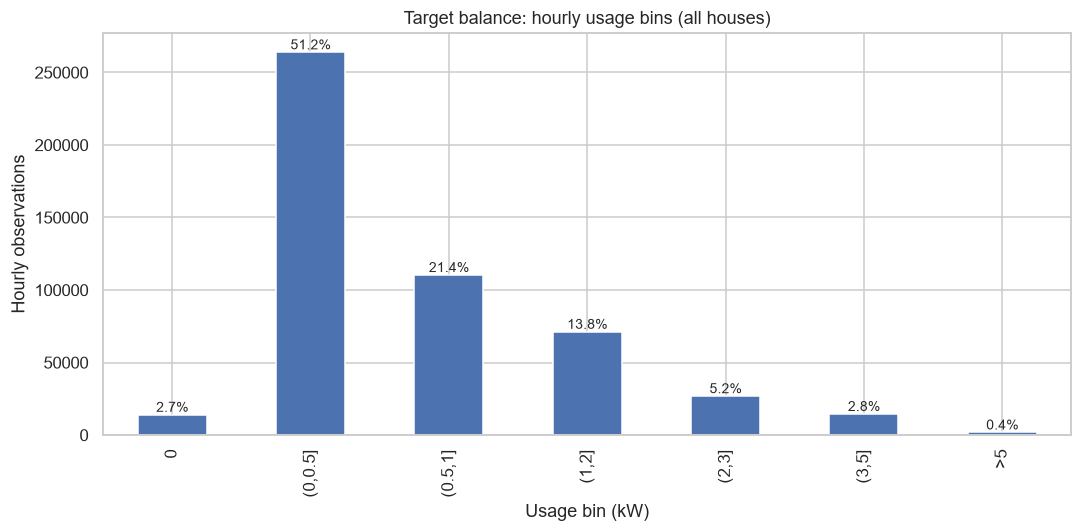

In [6]:
bins = [-0.001, 0.0, 0.5, 1.0, 2.0, 3.0, 5.0, np.inf]
labels = ["0", "(0,0.5]", "(0.5,1]", "(1,2]", "(2,3]", "(3,5]", ">5"]
binned = pd.cut(df["usage_kw"], bins=bins, labels=labels)
counts = binned.value_counts().reindex(labels)
plt.figure(figsize=(10, 5))
counts.plot(kind="bar", color="#4c72b0")
plt.title("Target balance: hourly usage bins (all houses)")
plt.xlabel("Usage bin (kW)")
plt.ylabel("Hourly observations")
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v / len(df) * 100:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "02_target_bins.png", dpi=220, bbox_inches="tight")
plt.show()

## Findings - Notebook 02

- Load profiles show a clear **evening peak** across cities; daytime usage is also driven by cooling (ACs) in warmer cities.
- City boxplots show **between-city differences** in median and spread of usage.
- The IQR analysis flags houses with many outliers - these may be genuine high-load events or sensor artefacts to handle in Phase 3.
- **Target balance**: most hours fall in low kW bins, with a long right tail - the model must handle skew (consider log or robust losses later).